<a href="https://colab.research.google.com/github/Preetish-ko/Preetish-ko/blob/main/Assignments/Assignment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3



# Question 1

You have two circles:

$$ \begin{align}
[x -2]^2 + y^2 &= 4 \\
x^2 + [y-3]^2 &= 4
\end{align} $$

and you want to find where they cross.

a) Write out $\vec{f}({\vec{x}})$

{answer}

In [4]:
import numpy as np

def f(x):
    return np.array([(x[0]-2)**2 + x[1]**2 - 4,
                     x[0]**2 + (x[1]-3)**2 - 4])

b) Write out the Jacobian $J(\vec{x})$

{answer}

In [5]:
def J(x):
    return np.array([[2*(x[0]-2), 2*x[1]],
                     [2*x[0],     2*(x[1]-3)]])

c) Write a Newton-Raphson method and use it to find where the circles cross (*Don't use a nonlinear solver package - show the algorithm down to the linear solver!*)

{implementation, answer x2}

In [7]:
# Linear solver: Gaussian elimination with partial pivoting
def solve_linear(A, b):
    A = np.array(A, dtype=float)
    b = np.array(b, dtype=float)
    n = len(b)

    # Forward elimination
    for k in range(n):
        p = k + np.argmax(np.abs(A[k:, k]))
        if abs(A[p, k]) < 1e-14:
            raise ValueError("Singular matrix")
        A[[k, p]] = A[[p, k]]
        b[[k, p]] = b[[p, k]]
        for i in range(k+1, n):
            m = A[i, k] / A[k, k]
            A[i, k:] -= m * A[k, k:]
            b[i]     -= m * b[k]

    # Back substitution
    x = np.zeros(n)
    for i in range(n-1, -1, -1):
        x[i] = (b[i] - A[i, i+1:] @ x[i+1:]) / A[i, i]
    return x

# Newton-Raphson
def newton(x0, tol=1e-12, maxit=50):
    x = np.array(x0, dtype=float)
    for it in range(1, maxit+1):
        delta = solve_linear(J(x), -f(x))
        x = x + delta
        print(f"iter {it:2d}: x = {x[0]:.10f}, y = {x[1]:.10f}, |delta| = {np.linalg.norm(delta):.2e}")
        if np.linalg.norm(delta) < tol:
            return x
    raise RuntimeError("Newton did not converge")

# Run from two starting guesses to find both intersections
p1 = newton([2, 2])
p2 = newton([0, 1])
print("Point 1:", p1)
print("Point 2:", p2)

iter  1: x = 1.7500000000, y = 2.0000000000, |delta| = 2.50e-01
iter  2: x = 1.7211538462, y = 1.9807692308, |delta| = 3.47e-02
iter  3: x = 1.7205769231, y = 1.9803846154, |delta| = 6.93e-04
iter  4: x = 1.7205766921, y = 1.9803844614, |delta| = 2.78e-07
iter  5: x = 1.7205766921, y = 1.9803844614, |delta| = 4.44e-14
iter  1: x = 0.2500000000, y = 1.0000000000, |delta| = 2.50e-01
iter  2: x = 0.2788461538, y = 1.0192307692, |delta| = 3.47e-02
iter  3: x = 0.2794230769, y = 1.0196153846, |delta| = 6.93e-04
iter  4: x = 0.2794233079, y = 1.0196155386, |delta| = 2.78e-07
iter  5: x = 0.2794233079, y = 1.0196155386, |delta| = 4.44e-14
Point 1: [1.72057669 1.98038446]
Point 2: [0.27942331 1.01961554]


# Question 2:

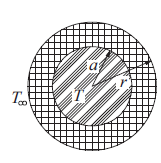

A wire carrying an electric current is surrounded by rubber insulation of outer radius $r$. The resistance of the wire generates heat, which is conducted through the insulation and convected into the surrounding air. The temperature of the wire can be shown to be:

$$ T = \frac{q}{2 \pi} \bigg[ \frac{ln(r/a)}{k} + \frac{1}{hr} \bigg] + T_\infty $$

where

- q = rate of heat generation in wire = 50 W/m
- a = radius of wire = 5mm
- k = thermal conductivity of rubber = 0.16 W/m · K
- h = convective heat-transfer coefficient = 20 W/m2 · K
- T∞ = ambient temperature = 280 K

Find $r$ that minimizes $T$

{method, imlementation, answer}


### Method
T(r) is smooth for r > a, so the minimum is where dT/dr = 0. Write c = q/(2π). Then:

T′(r) = c [ 1/(k r) − 1/(h r²) ]
T″(r) = c [ −1/(k r²) + 2/(h r³) ]

I find the root of T′(r) = 0 with Newton-Raphson in 1D, r_{n+1} = r_n − T′(r_n)/T″(r_n), then check that T″ > 0 so the root is a minimum.

### Implementation

In [8]:
import numpy as np

q, a, k, h, Tinf = 50.0, 0.005, 0.16, 20.0, 280.0
c = q / (2*np.pi)

def T(r):   return c*(np.log(r/a)/k + 1/(h*r)) + Tinf
def dT(r):  return c*(1/(k*r) - 1/(h*r**2))        # first derivative
def d2T(r): return c*(-1/(k*r**2) + 2/(h*r**3))    # second derivative

def newton_1d(r0, tol=1e-12, maxit=50):
    r = r0
    for it in range(1, maxit+1):
        dr = -dT(r) / d2T(r)
        r += dr
        print(f"iter {it}: r = {r:.10f} m, |dr| = {abs(dr):.2e}")
        if abs(dr) < tol:
            return r
    raise RuntimeError("No convergence")

r_opt = newton_1d(0.006)          # start between a and the expected answer
print("r_opt =", r_opt, "m")
print("T(r_opt) =", T(r_opt), "K")
print("T''(r_opt) =", d2T(r_opt), "(> 0, so it is a minimum)")

iter 1: r = 0.0072000000 m, |dr| = 1.20e-03
iter 2: r = 0.0078545455 m, |dr| = 6.55e-04
iter 3: r = 0.0079948052 m, |dr| = 1.40e-04
iter 4: r = 0.0079999933 m, |dr| = 5.19e-06
iter 5: r = 0.0080000000 m, |dr| = 6.74e-09
iter 6: r = 0.0080000000 m, |dr| = 1.14e-14
r_opt = 0.007999999999999998 m
T(r_opt) = 353.11198248671394 K
T''(r_opt) = 777123.7455658958 (> 0, so it is a minimum)


### Answer
Starting from r = 0.006 m, the first iterations by hand are 0.0072, then 0.007855, then 0.007995. The sequence converges quadratically to 0.008.

Answer

r = k/h = 0.16/20 = 0.008 m = 8 mm
The minimum wire temperature is T ≈ 353.1 K.
T″(r) > 0 there, so it is a true minimum.

Setting T′ = 0 analytically gives 1/(k r) = 1/(h r²), so r = k/h. This is the “critical radius of insulation”. Below 8 mm, adding insulation lowers the wire temperature because the larger outer surface improves convection by more than the extra conduction resistance costs. Above 8 mm, more insulation makes the wire hotter.

# Question 3:

{Method, answer}

Given the data in (T, k) columns,

In [10]:
import numpy as np
data = np.array([[2.73000000e+02, 4.45900132e+03],
       [2.76030303e+02, 4.41776331e+03],
       [2.79060606e+02, 7.02912764e+03],
       [2.82090909e+02, 8.07233255e+03],
       [2.85121212e+02, 1.35655353e+04],
       [2.88151515e+02, 1.53935301e+04],
       [2.91181818e+02, 1.66518521e+04],
       [2.94212121e+02, 2.57056205e+04],
       [2.97242424e+02, 2.80402378e+04],
       [3.00272727e+02, 3.52850720e+04],
       [3.03303030e+02, 2.53348206e+04],
       [3.06333333e+02, 6.20422294e+04],
       [3.09363636e+02, 5.65720969e+04],
       [3.12393939e+02, 8.94469023e+04],
       [3.15424242e+02, 9.65941942e+04],
       [3.18454545e+02, 1.14139663e+05],
       [3.21484848e+02, 1.00384893e+05],
       [3.24515152e+02, 1.60315046e+05],
       [3.27545455e+02, 1.75487522e+05],
       [3.30575758e+02, 2.79200552e+05],
       [3.33606061e+02, 2.83492579e+05],
       [3.36636364e+02, 2.19343286e+05],
       [3.39666667e+02, 3.46339717e+05],
       [3.42696970e+02, 3.29907107e+05],
       [3.45727273e+02, 2.99334626e+05],
       [3.48757576e+02, 4.85091915e+05],
       [3.51787879e+02, 7.28675595e+05],
       [3.54818182e+02, 9.91612106e+05],
       [3.57848485e+02, 9.39914377e+05],
       [3.60878788e+02, 1.46925677e+06],
       [3.63909091e+02, 1.46126057e+06],
       [3.66939394e+02, 1.35738053e+06],
       [3.69969697e+02, 1.14736966e+06],
       [3.73000000e+02, 2.10254656e+06],
       [3.76030303e+02, 1.12017395e+06],
       [3.79060606e+02, 2.34226319e+06],
       [3.82090909e+02, 2.22858410e+06],
       [3.85121212e+02, 3.26613076e+06],
       [3.88151515e+02, 3.68055559e+06],
       [3.91181818e+02, 2.37869512e+06],
       [3.94212121e+02, 4.10021974e+06],
       [3.97242424e+02, 3.84314791e+06],
       [4.00272727e+02, 6.46893402e+06],
       [4.03303030e+02, 5.35422811e+06],
       [4.06333333e+02, 7.73962115e+06],
       [4.09363636e+02, 8.41409713e+06],
       [4.12393939e+02, 7.81006766e+06],
       [4.15424242e+02, 8.35579617e+06],
       [4.18454545e+02, 1.03669786e+07],
       [4.21484848e+02, 1.02992887e+07],
       [4.24515152e+02, 6.39189417e+06],
       [4.27545455e+02, 1.36405449e+07],
       [4.30575758e+02, 1.49410729e+07],
       [4.33606061e+02, 2.09149077e+07],
       [4.36636364e+02, 2.14703032e+07],
       [4.39666667e+02, 2.11464887e+07],
       [4.42696970e+02, 2.60359855e+07],
       [4.45727273e+02, 3.19593647e+07],
       [4.48757576e+02, 2.84547486e+07],
       [4.51787879e+02, 2.98421720e+07],
       [4.54818182e+02, 3.54693846e+07],
       [4.57848485e+02, 4.17941703e+07],
       [4.60878788e+02, 4.65948030e+07],
       [4.63909091e+02, 5.74740135e+07],
       [4.66939394e+02, 4.12282427e+07],
       [4.69969697e+02, 6.43295352e+07],
       [4.73000000e+02, 6.78921367e+07],
       [4.76030303e+02, 6.87155479e+07],
       [4.79060606e+02, 6.70678776e+07],
       [4.82090909e+02, 6.23342574e+07],
       [4.85121212e+02, 9.48617775e+07],
       [4.88151515e+02, 9.34710486e+07],
       [4.91181818e+02, 8.25781385e+07],
       [4.94212121e+02, 1.02888832e+08],
       [4.97242424e+02, 9.99071191e+07],
       [5.00272727e+02, 1.01319698e+08],
       [5.03303030e+02, 1.32602108e+08],
       [5.06333333e+02, 1.31923942e+08],
       [5.09363636e+02, 1.00146518e+08],
       [5.12393939e+02, 1.48398130e+08],
       [5.15424242e+02, 2.01128065e+08],
       [5.18454545e+02, 2.25792703e+08],
       [5.21484848e+02, 1.99863590e+08],
       [5.24515152e+02, 2.47074414e+08],
       [5.27545455e+02, 2.08548654e+08],
       [5.30575758e+02, 1.83449792e+08],
       [5.33606061e+02, 2.58856094e+08],
       [5.36636364e+02, 3.10038100e+08],
       [5.39666667e+02, 3.58956357e+08],
       [5.42696970e+02, 3.21512830e+08],
       [5.45727273e+02, 4.30773903e+08],
       [5.48757576e+02, 4.39179856e+08],
       [5.51787879e+02, 4.57110476e+08],
       [5.54818182e+02, 3.75292342e+08],
       [5.57848485e+02, 3.97574548e+08],
       [5.60878788e+02, 4.57516936e+08],
       [5.63909091e+02, 2.63845055e+08],
       [5.66939394e+02, 4.59249219e+08],
       [5.69969697e+02, 5.23677345e+08],
       [5.73000000e+02, 7.51098462e+08]])

fit a modified Arrhenius curve of the form:

$$k = [A +B T]e^{\frac{-E}{RT}} $$

where $R$ is the Ideal gas constant.




# Method

The model is k(T) = (A + B·T)·exp(−E/(R·T)), with three unknowns A, B and E. I fit them by nonlinear least squares, with Gauss-Newton as the core and a Levenberg-Marquardt damping term so it doesn’t diverge from a poor starting guess.

####Residuals in log space.
The scatter in k looks multiplicative, with k spanning about 5 orders of magnitude, so a plain residual would let the high-T points dominate. I use rᵢ = ln kᵢ − ln(A + B·Tᵢ) + E/(R·Tᵢ).

####Jacobian.
With s = A + B·T, the columns are ∂r/∂A = −1/s, ∂r/∂B = −T/s, ∂r/∂E = 1/(R·T).

####Step.
Each iteration solves (JᵀJ + λ·diag(JᵀJ))·δ = −Jᵀr with the hand-written Gaussian elimination solver from Question 1, then updates p ← p + δ.

####Scaling.
A, B and E differ by about 10 orders of magnitude, so I work with parameters scaled by their starting values.

####Starting guess.
I take E from a linear fit of ln k against 1/T, the plain Arrhenius fit, which gives E ≈ 51 kJ/mol.

In [11]:
import numpy as np

# Assumes `data` (the Nx2 array of [T, k]) is already defined in an earlier cell
T, k = data[:, 0], data[:, 1]
R = 8.314  # J/(mol K)

# ---------- Linear solver: Gaussian elimination with partial pivoting ----------
def solve_linear(A, b):
    A = np.array(A, float); b = np.array(b, float); n = len(b)
    for j in range(n):
        p = j + np.argmax(abs(A[j:, j]))
        A[[j, p]] = A[[p, j]]; b[[j, p]] = b[[p, j]]
        for i in range(j+1, n):
            m = A[i, j] / A[j, j]
            A[i, j:] -= m * A[j, j:]; b[i] -= m * b[j]
    x = np.zeros(n)
    for i in range(n-1, -1, -1):
        x[i] = (b[i] - A[i, i+1:] @ x[i+1:]) / A[i, i]
    return x

# ---------- Model: k = (A + B T) exp(-E / (R T)), residuals in log space ----------
def resid(p):
    A, B, E = p
    return np.log(k) - np.log(A + B*T) + E/(R*T)

def jac(p):
    A, B, E = p; s = A + B*T
    return np.column_stack([-1/s, -T/s, 1/(R*T)])

def cost(p):
    return 0.5*np.sum(resid(p)**2) if np.all(p[0] + p[1]*T > 0) else np.inf

# ---------- Gauss-Newton with Levenberg-Marquardt damping ----------
def fit(p0, maxit=500, lam=1e-3):
    p = np.array(p0, float); sc = np.abs(p); c = cost(p)
    for it in range(maxit):
        Js = jac(p) * sc                       # scaled Jacobian
        H = Js.T @ Js; g = Js.T @ resid(p)
        while True:
            d = solve_linear(H + lam*np.diag(np.diag(H)), -g)
            pn = p + d*sc; cn = cost(pn)
            if cn < c: lam = max(lam/3, 1e-12); break
            lam *= 4                           # step rejected: damp more
        done = abs(c - cn) < 1e-15*c
        p, c = pn, cn
        if done: break
    return p, c

# ---------- Starting guess: plain Arrhenius (linear fit of ln k vs 1/T) ----------
slope = np.polyfit(1/T, np.log(k), 1)[0]
p0 = [1e12, 1e9, -slope*R]

p, c = fit(p0)
A, B, E = p
print(f"A = {A:.4e}")
print(f"B = {B:.4e}")
print(f"E = {E:.1f} J/mol")
print(f"rms log-residual = {np.sqrt(2*c/len(k)):.3f}")

A = -2.8951e+06
B = 2.4068e+10
E = 47962.4 J/mol
rms log-residual = 0.201
